In [1]:
import pandas as pd
import numpy as np
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer

In [2]:
df = pd.read_csv('./data/spotify_tracks.csv')
df.head(10)

,track_id,track_name,artist_name,album_name,release_year,genre,popularity,duration_ms,explicit,danceability,...,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,key,mode,time_signature
0,P3fAbnFbmOHnKYaXRvj7uf,One Dance (Acoustic Version),Alex Rodriguez,The Night Album,2024,metal,14,189042,True,0.427723,...,-4.702460,0.050635,0.239506,0.181395,0.133053,0.431384,141.048735,6,0,4
1,M2wleOV911xCZkwPRQeNHp,Forever Song (Remix),Desert Wind,Burning Soul,2019,rock,11,186805,True,0.448634,...,-7.110031,0.000000,0.044463,0.097818,0.435949,0.559135,131.833287,0,1,5
2,4JSnE2NiiUHUAKw9iEU1jj,Last Mountain,The Midnight,The Night Album,2022,k-pop,23,121814,False,0.707923,...,-7.305120,0.144091,0.118380,0.000000,0.262254,0.516873,127.132954,2,1,5
3,2UVvsjaSS8VFgM0Fmxk754,Falling Star (Live),Phantom Keys,Phantom's Greatest Hits,2024,latin,34,216049,False,0.846237,...,-9.527256,0.006668,0.272844,0.000000,0.045332,0.667911,93.041715,0,1,6
4,EeVVhDIq2AnHTmt9OBGhnu,Rising Moon (feat. someone),Desert Wind,Rising Soul,2010,latin,31,156170,False,0.943720,...,-9.017653,0.057632,0.219752,0.098044,0.132083,0.772151,93.404975,7,1,4
5,oPni6JDWYlgAACTP9gyv1p,Blue Moon (Live),Desert Wind,2007 Sessions,2007,electronic,9,256912,False,0.896756,...,-1.013697,0.063527,0.454676,0.176369,0.140136,0.590870,106.718743,11,1,4
6,Id9Z850kEnydx9qWCA79IS,Night Road (Remix),Desert Wind,Blue Heart,2021,electronic,8,195255,False,0.682981,...,-2.753794,0.063150,0.000000,0.291061,0.189708,0.745297,117.469204,5,0,4
7,GdF0ee1z6JJcfOJtqPtqiO,Forever Star,Jordan Johnson,The Night,2000,soul,68,273178,False,0.361379,...,-9.686549,0.048435,0.404352,0.026715,0.201494,0.346653,83.854148,11,0,4
8,22wjZRL9OaYsP6ihgIqLSm,Golden World (Live),Static Wave,Volume 1,2013,classical,16,169077,False,0.257228,...,-15.577083,0.052062,0.875835,0.806506,0.294282,0.562790,119.865479,7,0,4
9,TIAae24HZKjht3X13npgW2,Last Mountain,Crystal Veil,Dark Wave,2006,jazz,7,168838,False,0.490788,...,-6.880185,0.084944,0.651097,0.520757,0.244909,0.416569,128.045040,11,1,4


In [3]:
#Check for missing values. No missing values was found.
df.isnull().sum()

track_id            0
track_name          0
artist_name         0
album_name          0
release_year        0
genre               0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
key                 0
mode                0
time_signature      0
dtype: int64

In [4]:
#A summary of the dataset, including missing values, unique values, and data types for each column.
# It is noted that there is only 2400 unique values for track_name in 50000 rows, a further investigation is needed.
df_info = pd.DataFrame(
    {
     'Missing values': df.isna().sum(), 
     'Unique values': df.nunique(), 
     'dtype': df.dtypes
     }
)
df_info

,Missing values,Unique values,dtype
track_id,0,50000,str
track_name,0,2400,str
artist_name,0,415,str
album_name,0,481,str
release_year,0,25,int64
genre,0,20,str
popularity,0,106,int64
duration_ms,0,42848,int64
explicit,0,2,bool
danceability,0,49057,float64


In [5]:
#It is observed that the track "Silent Dance" have 85 occurrences in the dataset. 
# After further investigation, it was found that the track has different artists and albums. 
# This is probably due to the fact that the track has been covered by different artists or included in different albums.
# It is important to consider these factors when analyzing music data, as they can affect the popularity and success of a track.
df['track_name'].value_counts()
df[df['track_name'] == 'Silent Dance']

,track_id,track_name,artist_name,album_name,release_year,genre,popularity,duration_ms,explicit,danceability,...,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,key,mode,time_signature
1733,hHorbCsHIncu9vWXiEw3HS,Silent Dance,Reese Miller,The Rain Album,2024,indie,16,193337,False,0.690043,...,-6.939330,0.000000,0.391628,0.000000,0.428475,0.563075,134.022413,8,1,4
1911,5WcRE0u5wWuiQJrz30Rdru,Silent Dance,Echo Chamber,The Mountain Album,2020,hip-hop,20,232072,False,0.914330,...,-10.528235,0.220926,0.009443,0.000000,0.195166,0.465378,80.777867,11,0,4
2125,5IMz0NUmmaHOv1hC45SxAW,Silent Dance,Quinn Martin,The Star,2019,rock,36,193440,False,0.624550,...,-0.130900,0.081793,0.135587,0.061018,0.180213,0.772787,139.180817,10,0,4
2267,WlWur9cvsMEEd6HETzbCVK,Silent Dance,Velvet Underground,Velvet's Greatest Hits,2023,indie,11,150867,False,0.649942,...,-8.220586,0.058223,0.549091,0.056790,0.253676,0.566363,96.880007,5,0,4
2318,s90SuKjrgG8QL574XA3r2a,Silent Dance,Quinn Smith,The Storm Album,2018,country,9,141625,False,0.434122,...,-4.014488,0.044834,0.456547,0.083192,0.120061,0.807712,97.196552,9,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47614,dP1no5JMSME2oeGBVzTw2j,Silent Dance,Storm Collective,2021 Sessions,2021,drum-and-bass,7,365923,False,0.657545,...,-3.872815,0.037317,0.000000,0.361072,0.032308,0.371866,183.264705,2,1,4
48515,dV6XVN5Hu93Zpv7sxGiLNc,Silent Dance,Skyler Wilson,Skyler's Greatest Hits,2024,classical,26,257781,False,0.044872,...,-13.673285,0.000000,0.879630,0.974022,0.216754,0.338023,83.430248,7,0,4
49102,V63TXMYJ4Jjcabswh84Yt2,Silent Dance,Jamie Martinez,Volume 1,2008,latin,5,252956,False,0.835908,...,-2.732008,0.106600,0.067610,0.059055,0.180551,0.748820,130.746580,9,0,4
49726,TA3Zdjmv1Af9i2qrwNZwmZ,Silent Dance,Cameron Anderson,Electric Moon,2015,country,17,249564,False,0.761400,...,-11.306988,0.126083,0.484715,0.072256,0.099794,0.481244,124.886276,6,1,4


In [6]:
#For track_name, it is good to identify different versions of the same track, such as live, remix, etc.
track_names = list(df['track_name'])
#Split the track names into words and create a list
track_names_words = [word.strip().strip('(').strip(')') for name in track_names for word in name.split()]
track_names_words_counts = Counter(track_names_words)
print(track_names_words_counts)

#After analyzing the track names, the keywords "Remix", "Live", "Acoustic", "Version", "Radio Edit", "feat." worth further investigation.
keywords = ['Remix', 'Live', 'Acoustic', 'Version', 'Radio Edit', 'feat.']
track_names_with_keywords = [name for name in track_names if any(keyword in name for keyword in keywords)]

# All track names with "Version" keyword are pointing to acoustic versions of the track, so we can combine "Acoustic" and "Version" keywords.
track_names_with_version_keywords = [name for name in track_names_with_keywords if 'Version' in name]
track_names_with_version_keywords_not_acoustic = [name for name in track_names_with_version_keywords if 'Acoustic' not in name]
print(len(track_names_with_version_keywords_not_acoustic))

# Finalized keywords, create 5 new columns in the dataframe to indicate whether the track name contains any of the keywords.
keywords = ['Remix', 'Live', 'Acoustic Version', 'Radio Edit', 'feat.']
for keyword in keywords:
    df[f'keyword = {keyword}'] = df['track_name'].apply(lambda x: 1 if keyword in x else 0)

# Since track_name, track_id, and album_name should be unique for every song, these parameters will not be used as a feature in the model.
# Also, release_year is not related to the prediction of the popularity of a newly released track, so it will not be used as a feature in the model.
# This dataframe will be used for the tree based model.
df_data = df.drop(['track_name', 'track_id', 'album_name', 'release_year'], axis=1)
for col in df_data.columns:
    if df_data[col].dtype == 'str':
        df_data[col] = df_data[col].str.lower()
        df_data[col] = df_data[col].str.strip()

df_data.head(10)

Counter({'Remix': 5703, 'Live': 5625, 'Acoustic': 5531, 'Version': 5531, '-': 5501, 'Radio': 5501, 'Edit': 5501, 'feat.': 5465, 'someone': 5465, 'Night': 4995, 'Silent': 2582, 'Falling': 2581, 'Heart': 2573, 'Star': 2565, 'Dance': 2555, 'Dream': 2549, 'Dark': 2541, 'Moon': 2538, 'The': 2538, 'Broken': 2534, 'Soul': 2534, 'Forever': 2532, 'Slow': 2528, 'World': 2524, 'Day': 2523, 'Mountain': 2511, 'Fire': 2507, 'Sky': 2505, 'Wild': 2502, 'Blue': 2500, 'Your': 2500, 'Road': 2495, 'Fast': 2494, 'Last': 2489, 'One': 2487, 'Wave': 2477, 'Rising': 2475, 'Song': 2471, 'River': 2460, 'Burning': 2458, 'Golden': 2456, 'Light': 2454, 'Electric': 2449, 'My': 2437, 'Rain': 2433, 'Storm': 2418, 'Lost': 2416, 'Love': 2414})
0


,artist_name,genre,popularity,duration_ms,explicit,danceability,energy,loudness,speechiness,acousticness,...,valence,tempo,key,mode,time_signature,keyword = Remix,keyword = Live,keyword = Acoustic Version,keyword = Radio Edit,keyword = feat.
0,alex rodriguez,metal,14,189042,True,0.427723,1.000000,-4.702460,0.050635,0.239506,...,0.431384,141.048735,6,0,4,0,0,1,0,0
1,desert wind,rock,11,186805,True,0.448634,0.730911,-7.110031,0.000000,0.044463,...,0.559135,131.833287,0,1,5,1,0,0,0,0
2,the midnight,k-pop,23,121814,False,0.707923,0.744997,-7.305120,0.144091,0.118380,...,0.516873,127.132954,2,1,5,0,0,0,0,0
3,phantom keys,latin,34,216049,False,0.846237,0.855811,-9.527256,0.006668,0.272844,...,0.667911,93.041715,0,1,6,0,1,0,0,0
4,desert wind,latin,31,156170,False,0.943720,0.861754,-9.017653,0.057632,0.219752,...,0.772151,93.404975,7,1,4,0,0,0,0,1
5,desert wind,electronic,9,256912,False,0.896756,0.945471,-1.013697,0.063527,0.454676,...,0.590870,106.718743,11,1,4,0,1,0,0,0
6,desert wind,electronic,8,195255,False,0.682981,0.789789,-2.753794,0.063150,0.000000,...,0.745297,117.469204,5,0,4,1,0,0,0,0
7,jordan johnson,soul,68,273178,False,0.361379,0.621462,-9.686549,0.048435,0.404352,...,0.346653,83.854148,11,0,4,0,0,0,0,0
8,static wave,classical,16,169077,False,0.257228,0.545589,-15.577083,0.052062,0.875835,...,0.562790,119.865479,7,0,4,0,1,0,0,0
9,crystal veil,jazz,7,168838,False,0.490788,0.510780,-6.880185,0.084944,0.651097,...,0.416569,128.045040,11,1,4,0,0,0,0,0


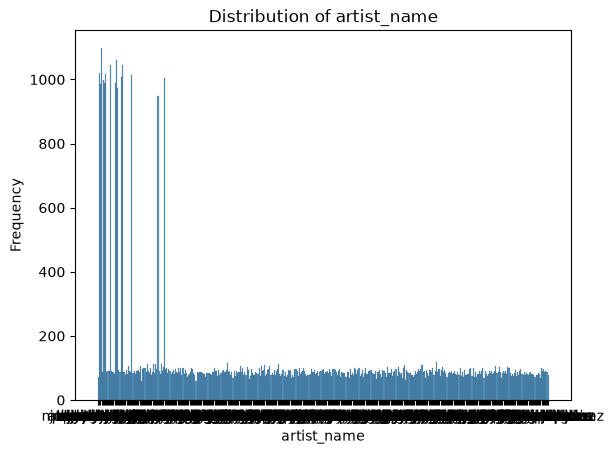

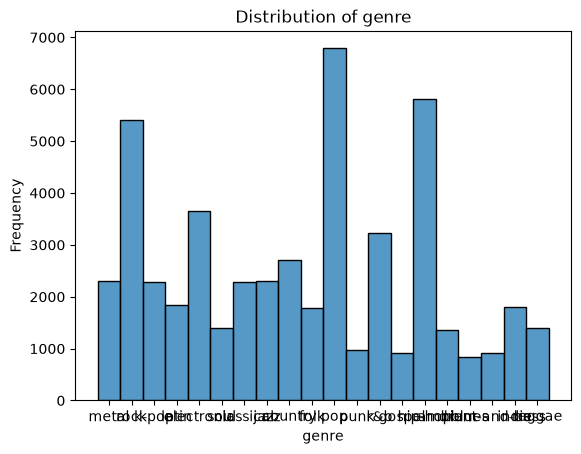

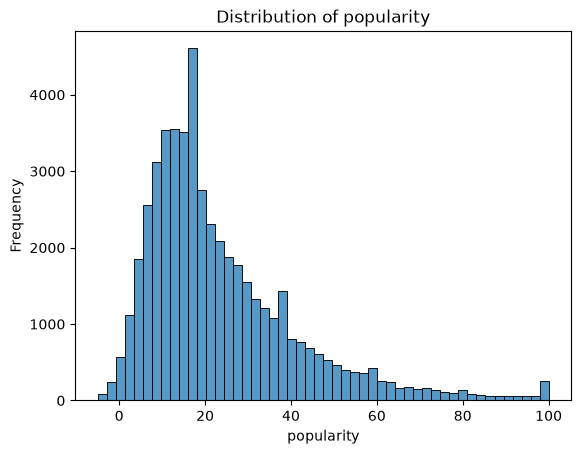

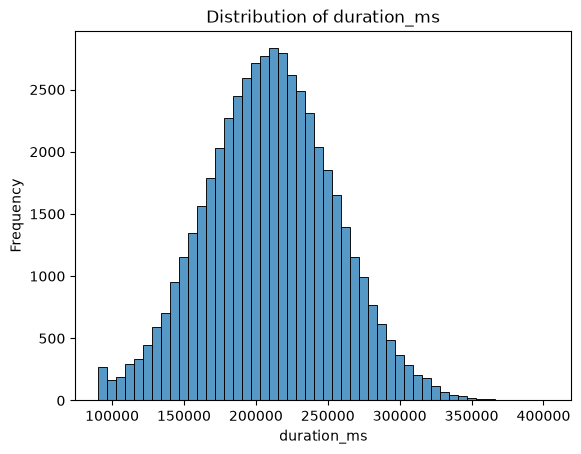

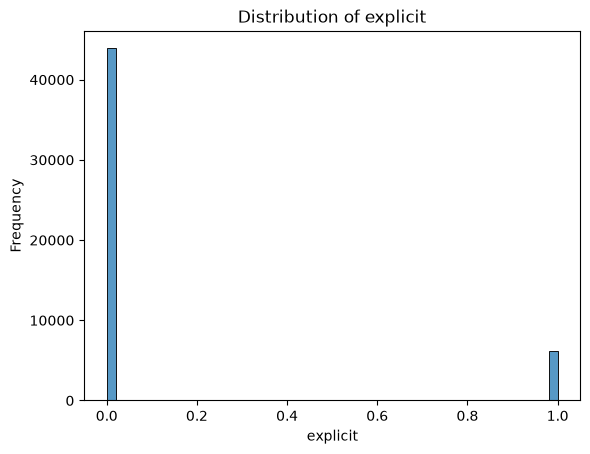

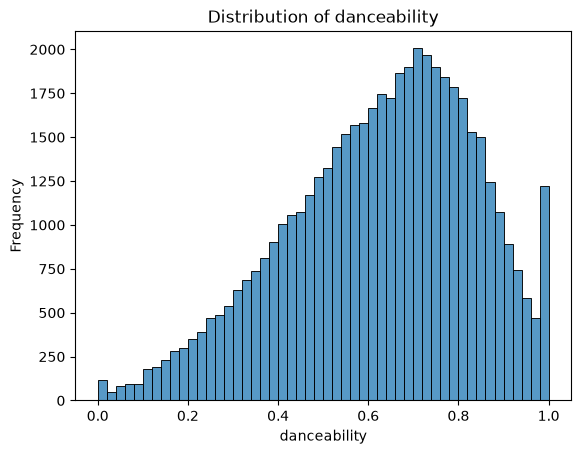

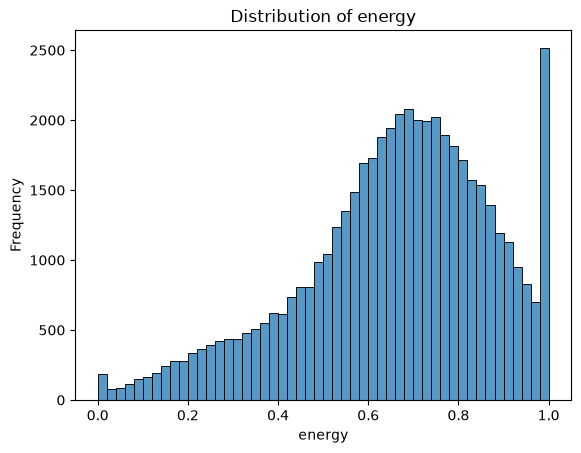

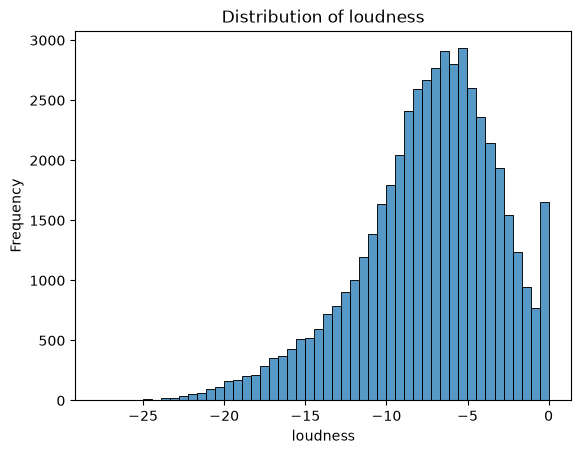

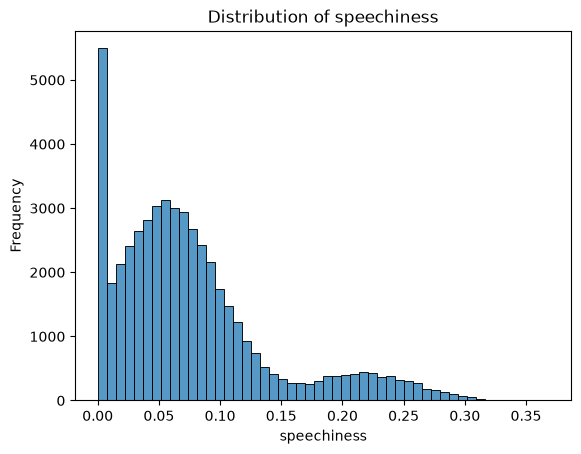

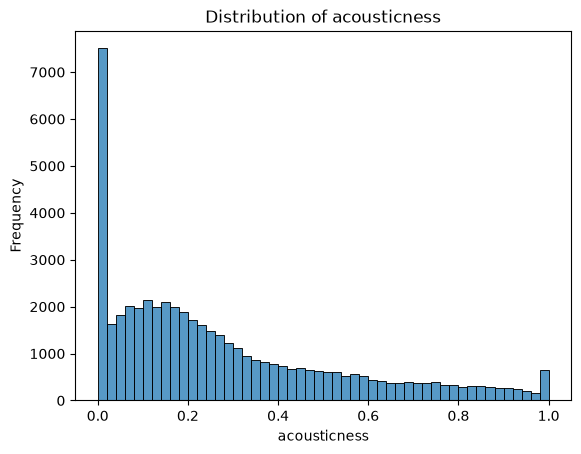

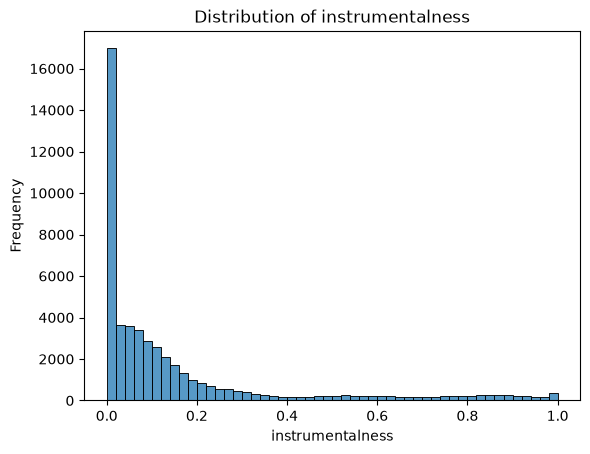

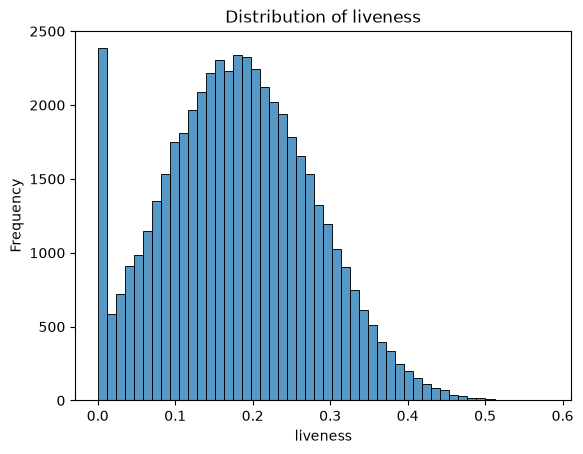

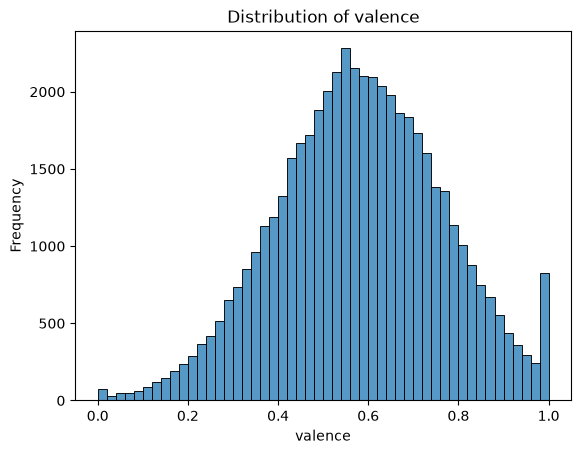

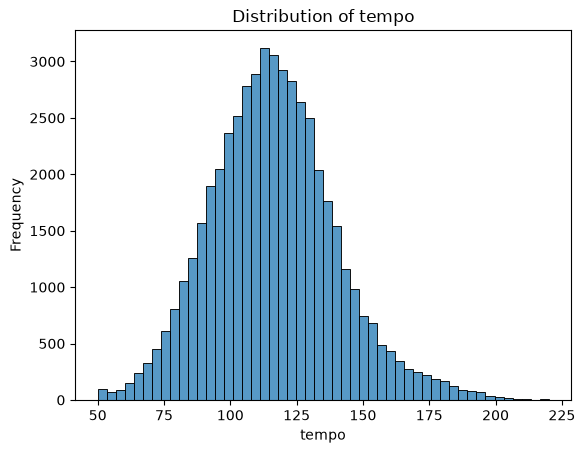

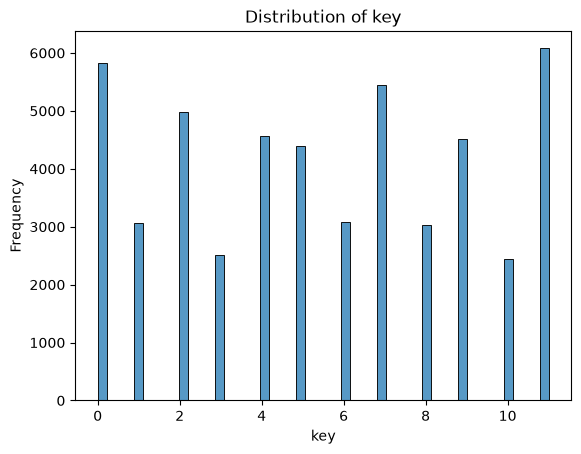

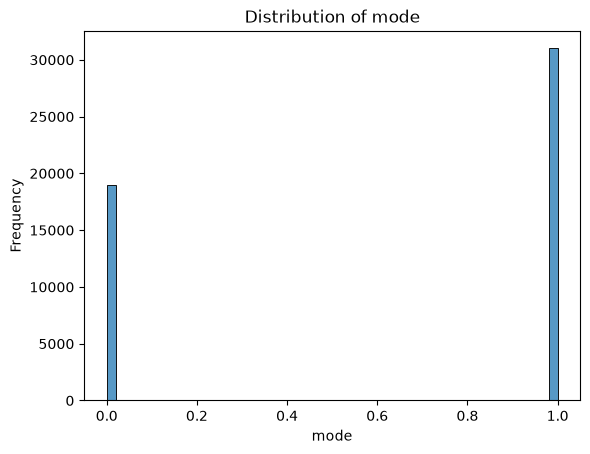

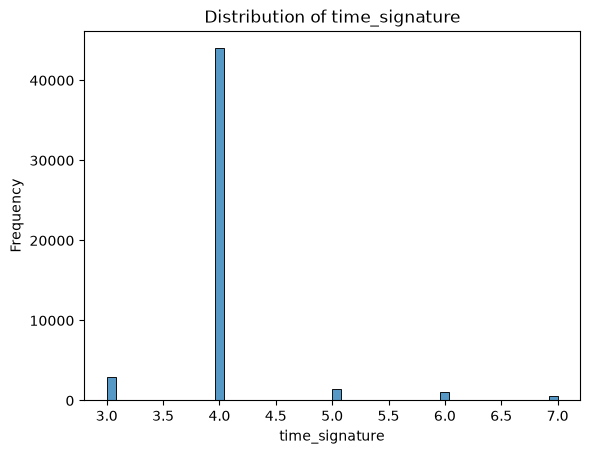

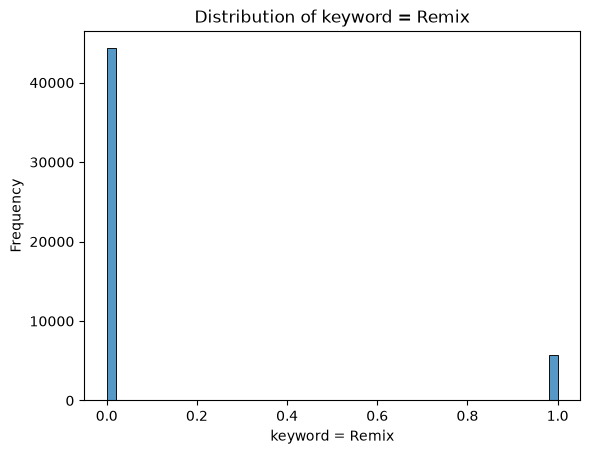

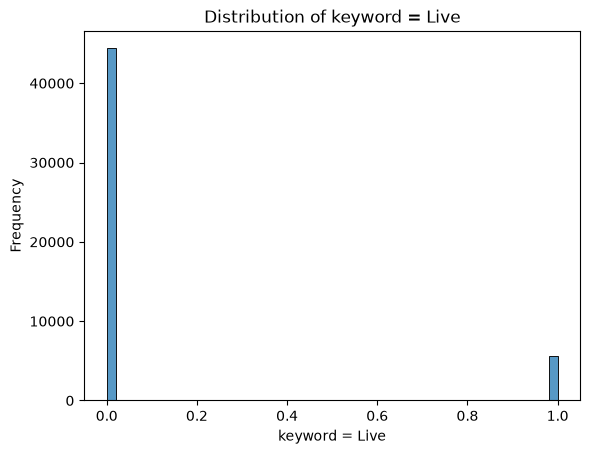

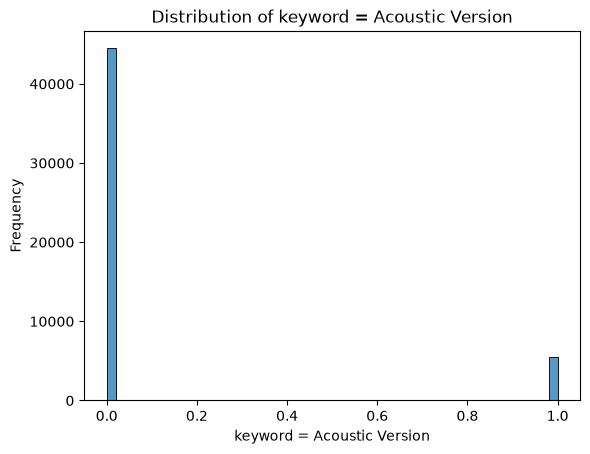

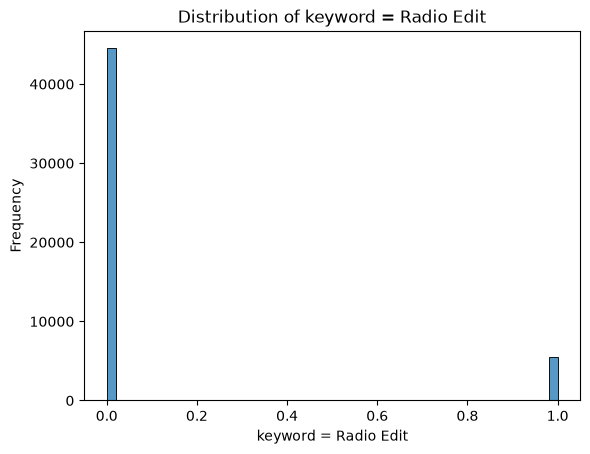

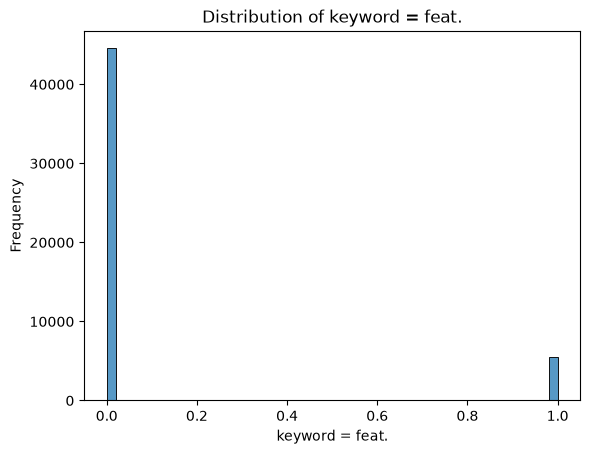

In [7]:
# Plotting the distribution of each column.
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

for col in df_data.columns:
    sns.histplot(df_data[col], bins=50)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()


In [8]:
# Correlation of numerical features with popularity.
# The resulting correlation values are found to be very low, using linear regression model for prediction of popularity may result in low accuracy.
numerical = df_data.select_dtypes(include=[np.number]).columns.tolist()

df_data[numerical].corrwith(df_data['popularity']).sort_values(ascending=False)

popularity                    1.000000
time_signature                0.004955
danceability                  0.002480
keyword = feat.               0.002335
keyword = Live                0.002235
keyword = Acoustic Version    0.001907
acousticness                  0.001763
key                           0.001693
mode                          0.000549
loudness                      0.000255
tempo                         0.000059
liveness                     -0.000698
speechiness                  -0.001894
valence                      -0.002257
energy                       -0.002290
duration_ms                  -0.003588
instrumentalness             -0.004172
keyword = Radio Edit         -0.004514
keyword = Remix              -0.005937
dtype: float64

In [9]:
# Train/validation/test split and prepare the data for modeling. The target variable is "popularity".
df_full_train, df_test = train_test_split(df_data, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['popularity'].values
y_val = df_val['popularity'].values
y_test = df_test['popularity'].values

df_train = df_train.drop('popularity', axis=1)
df_val = df_val.drop('popularity', axis=1)
df_test = df_test.drop('popularity', axis=1)

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train.to_dict(orient='records'))
X_val = dv.transform(df_val.to_dict(orient='records'))
X_test = dv.transform(df_test.to_dict(orient='records'))

In [10]:
from sklearn.feature_selection import mutual_info_regression

# feature-importance analysis
feature_names = dv.get_feature_names_out()

discrete_mask = np.array([
    '=' in name for name in feature_names
])

mi_scores = mutual_info_regression(
    X_train,
    y_train,
    discrete_features=discrete_mask,
    random_state=1
)

mi_results = pd.Series(
    mi_scores,
    index=feature_names
).sort_values(ascending=False)

print(mi_results.head(20))

duration_ms                0.010745
acousticness               0.007470
speechiness                0.005877
time_signature             0.004861
genre=hip-hop              0.004318
tempo                      0.004166
mode                       0.002906
keyword = Remix            0.002683
explicit                   0.002574
key                        0.002400
genre=pop                  0.002153
keyword = Live             0.001939
genre=electronic           0.001720
keyword = feat.            0.001709
genre=gospel               0.001102
genre=metal                0.000944
artist_name=desert wind    0.000920
artist_name=sam johnson    0.000820
genre=reggae               0.000778
artist_name=drew garcia    0.000757
dtype: float64


In [11]:
# Train a linear regression model and evaluate its performance using RMSE.
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

y_pred_lr_train = model_lr.predict(X_train)
rmse_lr_train = np.sqrt(np.mean((y_train - y_pred_lr_train) ** 2))
print(f'RMSE for train dataset: {rmse_lr_train:.2f}')

y_pred_lr_val = model_lr.predict(X_val)
rmse_lr_val = np.sqrt(np.mean((y_val - y_pred_lr_val) ** 2))
print(f'RMSE for validation dataset: {rmse_lr_val:.2f}')

#RMSE for train dataset: 17.85
#RMSE for validation dataset: 17.83 

RMSE for train dataset: 17.85
RMSE for validation dataset: 17.83


In [12]:
# Train a tree based model and evaluate its performance using RMSE.
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(random_state=1)
model_rf.fit(X_train, y_train)

y_pred_rf_train = model_rf.predict(X_train)
rmse_rf_train = np.sqrt(np.mean((y_train - y_pred_rf_train) ** 2))
print(f'RMSE for train dataset: {rmse_rf_train:.2f}')

y_pred_rf_val = model_rf.predict(X_val)
rmse_rf_val = np.sqrt(np.mean((y_val - y_pred_rf_val) ** 2))
print(f'RMSE for validation dataset: {rmse_rf_val:.2f}')
#RMSE for train dataset: 6.81
#RMSE for validation dataset: 18.07

RMSE for train dataset: 6.81
RMSE for validation dataset: 18.07


In [13]:
#Train a xgboost model and evaluate its performance using RMSE.
import xgboost as xgb

model_xgb = xgb.XGBRegressor(
    random_state=1,
    objective='reg:squarederror'
)
model_xgb.fit(X_train, y_train)

y_pred_xgb_train = model_xgb.predict(X_train)
rmse_xgb_train = np.sqrt(np.mean((y_train - y_pred_xgb_train) ** 2))
print(f'RMSE for train dataset: {rmse_xgb_train:.2f}')

y_pred_xgb_val = model_xgb.predict(X_val)
rmse_xgb_val = np.sqrt(np.mean((y_val - y_pred_xgb_val) ** 2))
print(f'RMSE for validation dataset: {rmse_xgb_val:.2f}')
#RMSE for train dataset: 15.53
#RMSE for validation dataset: 18.27

RMSE for train dataset: 15.53
RMSE for validation dataset: 18.27


In [14]:
from sklearn.model_selection import KFold, RandomizedSearchCV

# Refit DictVectorizer using the complete training dataset
dv_final = DictVectorizer(sparse=False)

X_full_train = dv_final.fit_transform(
    df_full_train.drop('popularity', axis=1).to_dict(orient='records')
)

y_full_train = df_full_train['popularity'].values

# 5-fold cross-validation
kfold = KFold(
    n_splits=3,
    shuffle=True,
    random_state=1
)

In [15]:
rf_params = {
    'n_estimators': [200, 300, 500],
    'max_depth': [None, 10, 20, 30],
    'min_samples_leaf': [1, 2, 5],
    'max_features': [0.7, 1.0, 'sqrt']
}

search_rf = RandomizedSearchCV(
    RandomForestRegressor(random_state=1, n_jobs=1),
    param_distributions=rf_params,
    n_iter=5,
    scoring='neg_root_mean_squared_error',
    cv=kfold,
    random_state=1,
    n_jobs=-1,
    verbose=2
)

search_rf.fit(X_full_train, y_full_train)

print('Best RF parameters:', search_rf.best_params_)
print('Best RF CV RMSE:', -search_rf.best_score_)

# Best RF parameters: {'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30}
# Best RF CV RMSE: 17.89219785997196

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best RF parameters: {'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30}
Best RF CV RMSE: 17.89219785997196


In [16]:
xgb_params = {
    'n_estimators': [200, 400, 600],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 5]
}

search_xgb = RandomizedSearchCV(
    xgb.XGBRegressor(
        objective='reg:squarederror',
        random_state=1,
        n_jobs=1
    ),
    param_distributions=xgb_params,
    n_iter=8,
    scoring='neg_root_mean_squared_error',
    cv=kfold,
    random_state=1,
    n_jobs=-1,
    verbose=1
)

search_xgb.fit(X_full_train, y_full_train)

print('Best XGB parameters:', search_xgb.best_params_)
print('Best XGB CV RMSE:', -search_xgb.best_score_)

# Best XGB parameters: {'subsample': 0.8, 'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
# Best XGB CV RMSE: 17.931679407755535

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best XGB parameters: {'subsample': 0.8, 'n_estimators': 600, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Best XGB CV RMSE: 17.931679407755535


In [17]:
# Select the model with the lowest CV RMSE
if search_rf.best_score_ > search_xgb.best_score_:
    best_model = search_rf.best_estimator_
    best_name = 'Random Forest'
else:
    best_model = search_xgb.best_estimator_
    best_name = 'XGBoost'

# Transform test data using the final vectorizer
X_test_final = dv_final.transform(
    df_test.to_dict(orient='records')
)

# Evaluate on untouched test dataset
y_pred_test = best_model.predict(X_test_final)

rmse_test = np.sqrt(
    np.mean((y_test - y_pred_test) ** 2)
)

mae_test = np.mean(
    np.abs(y_test - y_pred_test)
)

print(f'Best model: {best_name}')
print(f'Test RMSE: {rmse_test:.2f}')
print(f'Test MAE: {mae_test:.2f}')

#Result:
# Best model: Random Forest
# Test RMSE: 18.13
# Test MAE: 13.51

Best model: Random Forest
Test RMSE: 18.13
Test MAE: 13.51
